In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import joblib

from sklearn.model_selection import train_test_split , RepeatedStratifiedKFold , cross_validate , GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler , OneHotEncoder , FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.metrics import classification_report , ConfusionMatrixDisplay , RocCurveDisplay , roc_auc_score
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv(r"archive\Heart Attack Data Set.csv")

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [5]:
df.shape

(303, 14)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

### **Data Cleaning**

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(1)

In [11]:
df[df.duplicated(keep= False)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [12]:
df.drop_duplicates(inplace= True)
df.reset_index(drop= True , inplace= True)
df.shape

(302, 14)

In [13]:
df['ca'].value_counts().sort_index()

ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

In [14]:
df['thal'].value_counts().sort_index()

thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64

In [15]:
df['ca'] = df['ca'].replace(4 , np.nan)
df['thal'] = df['thal'].replace(0 , np.nan)

df.isnull().sum()[df.isnull().sum() > 0]

ca      4
thal    2
dtype: int64

In [16]:
binary_features = ['sex' , 'fbs' , 'exang']

df[binary_features + ['target']].isin([0 , 1]).all().all()

np.True_

In [17]:
cont_cols = ['age' , 'trestbps' , 'chol' , 'thalach' , 'oldpeak']

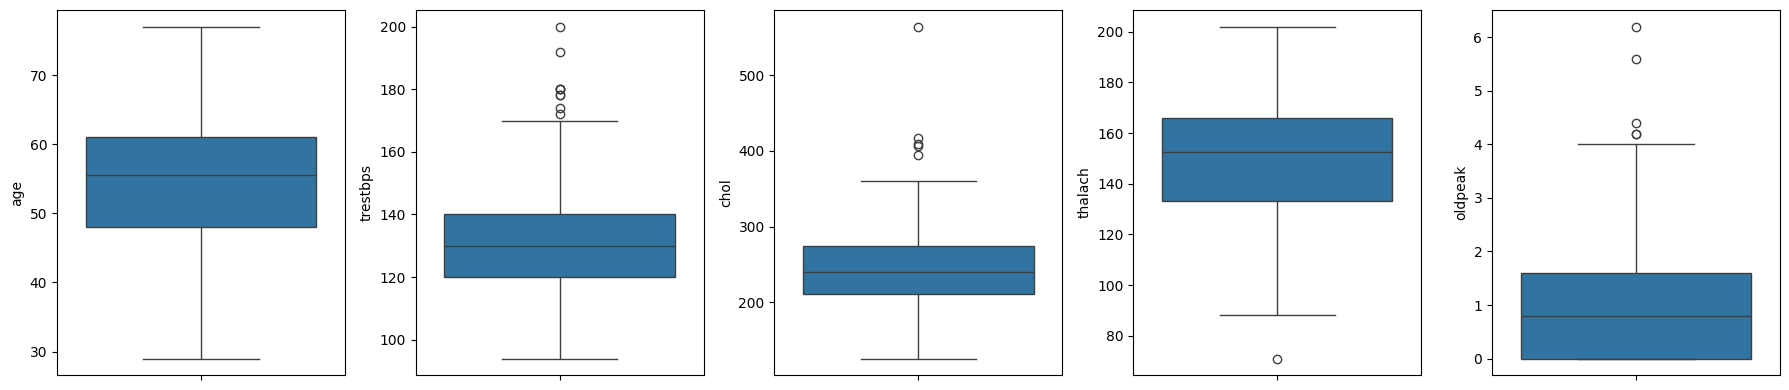

In [18]:
plt.figure(figsize= (18, 4))
for i, col in enumerate(cont_cols):
    plt.subplot(1, 5, i + 1)
    sns.boxplot(y= df[col])
plt.tight_layout()
plt.show()

In [19]:
for col in cont_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)].shape[0]
    if outliers > 0:
        print(col , outliers)

trestbps 9
chol 5
thalach 1
oldpeak 5


### **EDA && Visualization**

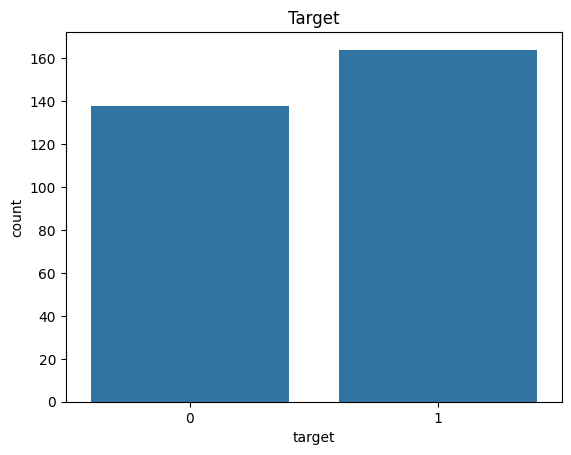

In [20]:
sns.countplot( x = 'target' , data= df)
plt.title('Target')
plt.show()

In [21]:
df['target'].value_counts()

target
1    164
0    138
Name: count, dtype: int64

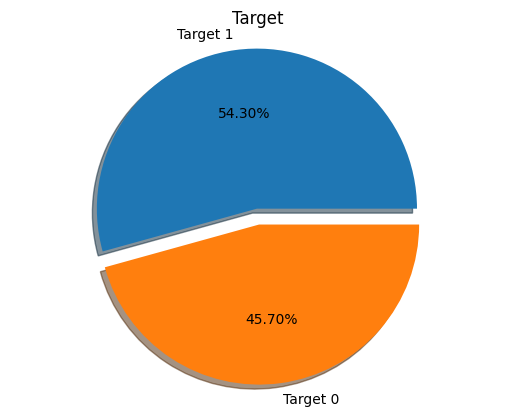

In [22]:
plt.pie(df['target'].value_counts() , 
        labels = ['Target ' + str(i) for i in df['target'].value_counts().index] , 
        autopct = '%1.2f%%' , 
        shadow = True , 
        explode = [0 , 0.1])
plt.title('Target')
plt.axis('equal')
plt.show()

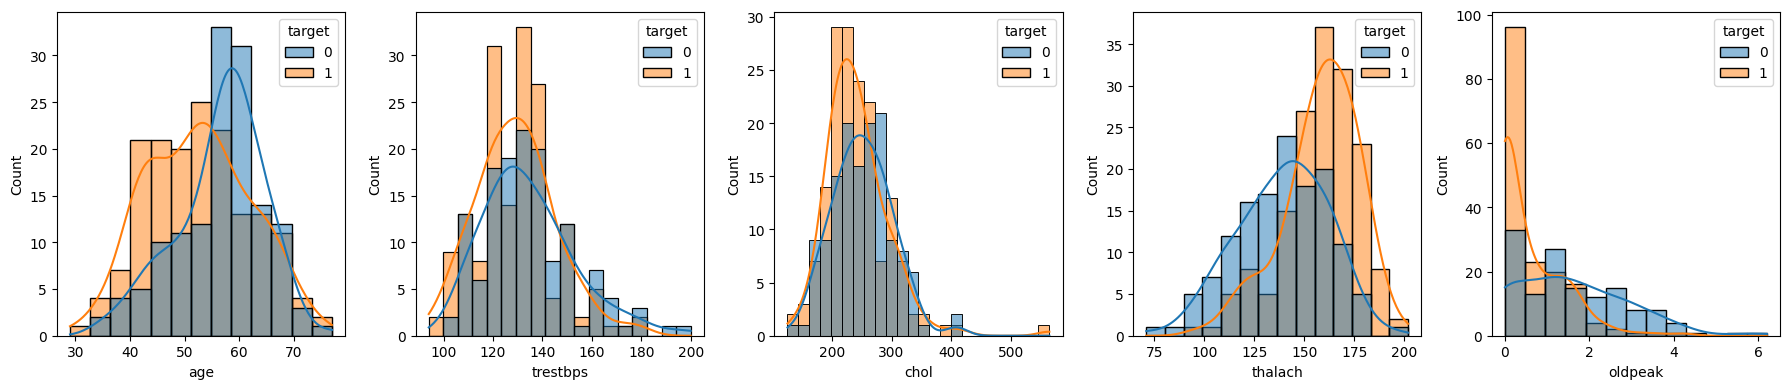

In [23]:
plt.figure(figsize= (18, 4))
for i, col in enumerate(cont_cols):
    plt.subplot(1, 5, i + 1)
    sns.histplot(data= df , x= col , hue= 'target' , kde= True)
plt.tight_layout()
plt.show()

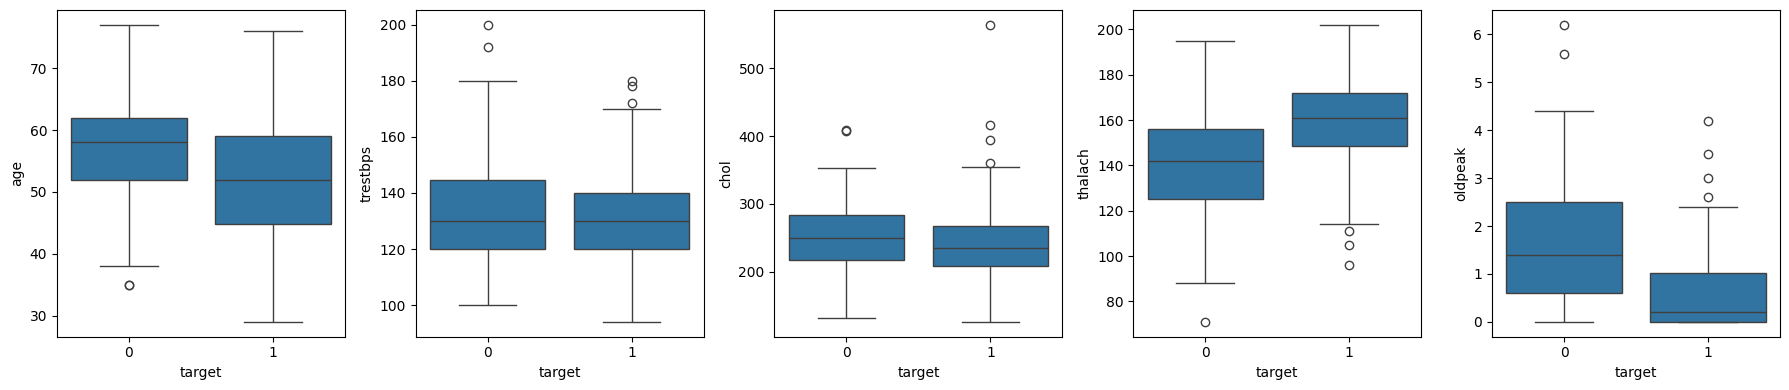

In [24]:
plt.figure(figsize= (18, 4))
for i, col in enumerate(cont_cols):
    plt.subplot(1, 5, i + 1)
    sns.boxplot(x= 'target' , y= col , data= df)
plt.tight_layout()
plt.show()

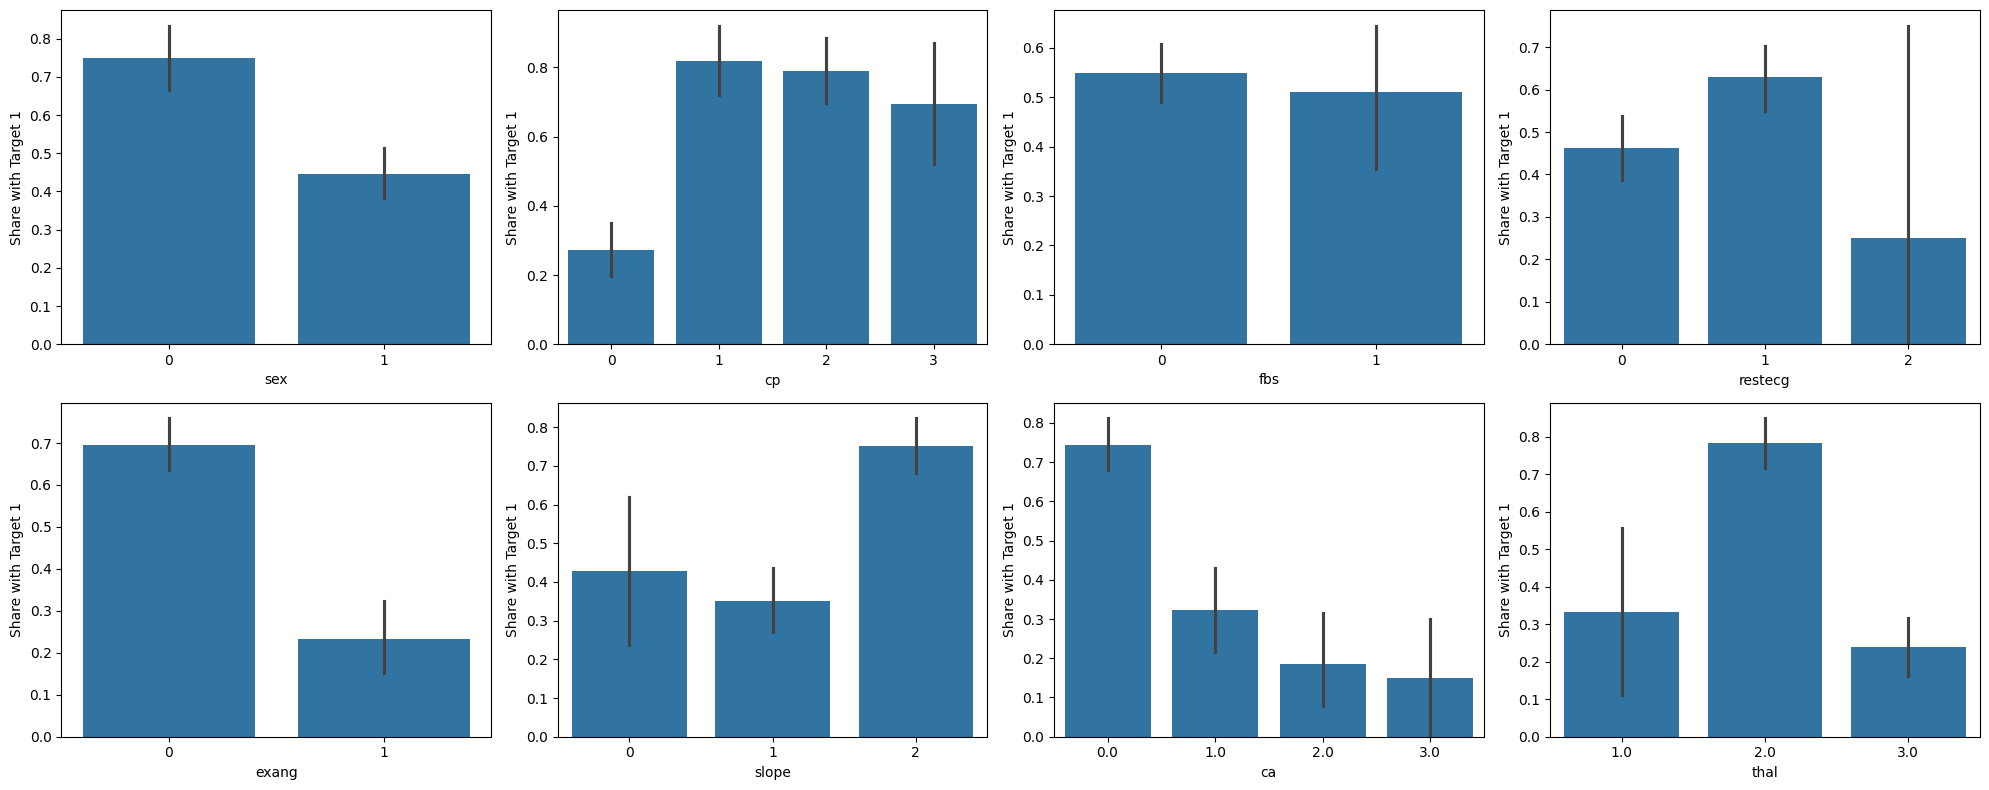

In [25]:
cat_cols = ['sex' , 'cp' , 'fbs' , 'restecg' , 'exang' , 'slope' , 'ca' , 'thal']

plt.figure(figsize= (20, 8))
for i, col in enumerate(cat_cols):
    plt.subplot(2, 4, i + 1)
    sns.barplot(x= col , y= 'target' , data= df)
    plt.ylabel('Share with Target 1')
plt.tight_layout()
plt.show()

In [26]:
df.groupby('target').mean().T.round(2)

target,0,1
age,56.60,52.59
sex,0.83,0.56
cp,0.48,1.37
trestbps,134.40,129.25
chol,251.09,242.64
fbs,0.16,0.14
restecg,0.45,0.59
thalach,139.10,158.38
exang,0.55,0.14
oldpeak,1.59,0.59


In [27]:
df[cont_cols].skew()

age        -0.203743
trestbps    0.716541
chol        1.147332
thalach    -0.532671
oldpeak     1.266173
dtype: float64

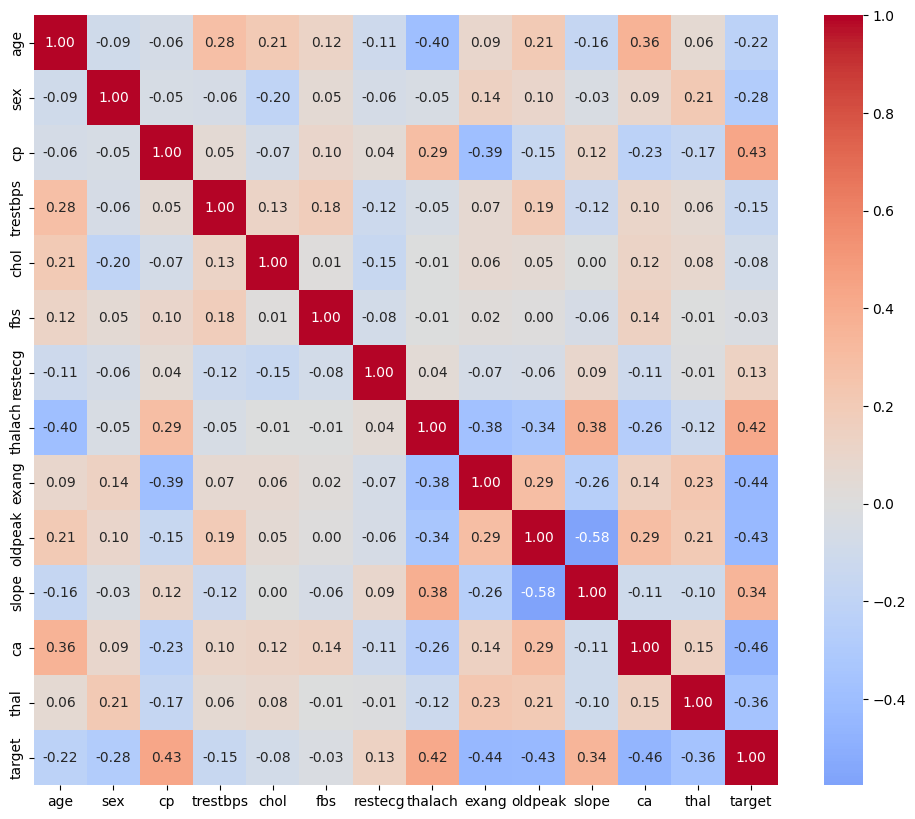

In [28]:
plt.figure(figsize= (12,10))
sns.heatmap (df.corr() , annot= True , fmt= '.2f' , cmap= 'coolwarm' , center= 0)
plt.show()

In [29]:
df.corr()['target'].drop('target').sort_values()

ca         -0.464357
exang      -0.435601
oldpeak    -0.429146
thal       -0.364247
sex        -0.283609
age        -0.221476
trestbps   -0.146269
chol       -0.081437
fbs        -0.026826
restecg     0.134874
slope       0.343940
thalach     0.419955
cp          0.432080
Name: target, dtype: float64

In [30]:
X = df.drop(columns= 'target')
y = df['target']

In [31]:
skewed_features = ['chol' , 'oldpeak']
num_features = ['age' , 'trestbps' , 'thalach']
cat_features = ['cp' , 'restecg' , 'slope' , 'thal']
ordinal_features = ['ca']

In [32]:
preprocessor = ColumnTransformer([
    ('skewed' , Pipeline([('log' , FunctionTransformer(np.log1p)) , ('scale' , StandardScaler())]) , skewed_features) ,
    ('num' , StandardScaler() , num_features) ,
    ('ordinal' , Pipeline([('impute' , SimpleImputer(strategy= 'most_frequent')) , ('scale' , StandardScaler())]) , ordinal_features) ,
    ('cat' , Pipeline([('impute' , SimpleImputer(strategy= 'most_frequent')) , ('onehot' , OneHotEncoder(handle_unknown= 'ignore'))]) , cat_features) ,
    ('binary' , 'passthrough' , binary_features)
])

### **Train Test Split**

In [33]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size= 0.2 , random_state= 42 , stratify= y)

In [34]:
X_train.shape , X_test.shape

((241, 13), (61, 13))

In [35]:
y_train.mean() , y_test.mean()

(np.float64(0.5435684647302904), np.float64(0.5409836065573771))

### **Model Training**

In [36]:
models = {
    'Logistic Regression': LogisticRegression(max_iter= 1000) ,
    'KNN': KNeighborsClassifier() ,
    'SVM': SVC(probability= True , random_state= 42) ,
    'Random Forest': RandomForestClassifier(random_state= 42) ,
    'Gradient Boosting': GradientBoostingClassifier(random_state= 42)
}

cv = RepeatedStratifiedKFold(n_splits= 5 , n_repeats= 3 , random_state= 42)

In [37]:
scores = {}
metrics = ['roc_auc' , 'recall' , 'precision' , 'f1' , 'accuracy']
for name, model in models.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , model)])
    result = cross_validate(pipe , X_train , y_train , cv= cv , scoring= metrics)
    scores[name] = {metric: result['test_' + metric].mean() for metric in metrics}

baseline = pd.DataFrame(scores).T.sort_values('roc_auc' , ascending= False)
baseline.round(3)

,roc_auc,recall,precision,f1,accuracy
Logistic Regression,0.905,0.873,0.842,0.856,0.840
SVM,0.898,0.891,0.828,0.857,0.838
Random Forest,0.896,0.852,0.836,0.841,0.824
Gradient Boosting,0.877,0.822,0.820,0.818,0.804
KNN,0.876,0.858,0.833,0.844,0.827


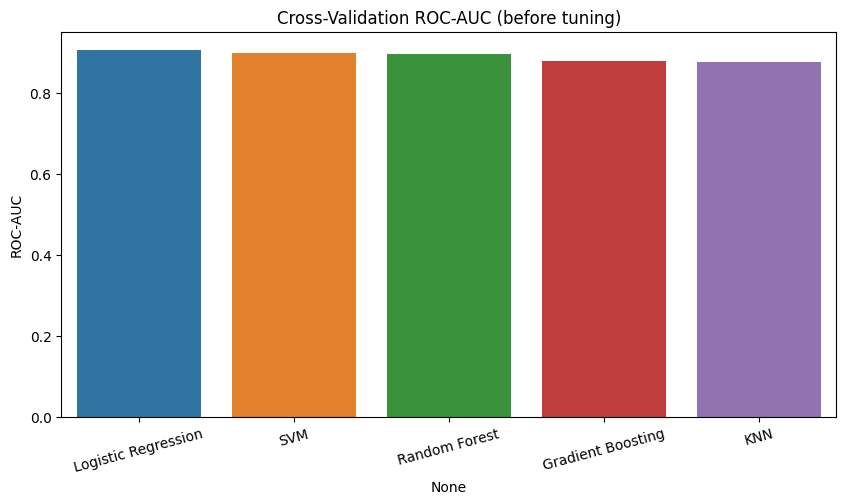

In [38]:
plt.figure(figsize= (10,5))
plt.title('Cross-Validation ROC-AUC (before tuning)')
sns.barplot( x = baseline.index , y= baseline['roc_auc'] , hue= baseline.index)
plt.ylabel('ROC-AUC')
plt.xticks(rotation= 15)
plt.show()

In [39]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01 , 0.1 , 0.5 , 1 , 5 , 10]} ,
    'SVM': {'model__C': [0.1 , 0.5 , 1 , 5] , 'model__gamma': ['scale' , 0.01 , 0.05 , 0.1]} ,
    'Random Forest': {'model__n_estimators': [200] , 'model__max_depth': [3 , 5 , None] , 'model__min_samples_leaf': [1 , 3 , 5]}
}

grid_results = {}
for name, grid in param_grids.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , models[name])])
    grid_results[name] = GridSearchCV(pipe , grid , cv= cv , scoring= 'roc_auc' , n_jobs= -1).fit(X_train , y_train)
    print(name , round(grid_results[name].best_score_ , 3) , grid_results[name].best_params_)

Logistic Regression 0.912 {'model__C': 0.1}
SVM 0.909 {'model__C': 0.5, 'model__gamma': 0.01}
Random Forest 0.914 {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}


In [40]:
best_name = max(grid_results , key= lambda name: grid_results[name].best_score_)
final_model = grid_results[best_name].best_estimator_
best_name

'Random Forest'

### **Model Evaluation**

In [41]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[: , 1]

print(classification_report(y_test , y_pred , target_names= ['Target 0' , 'Target 1']))

              precision    recall  f1-score   support

    Target 0       0.82      0.64      0.72        28
    Target 1       0.74      0.88      0.81        33

    accuracy                           0.77        61
   macro avg       0.78      0.76      0.76        61
weighted avg       0.78      0.77      0.77        61



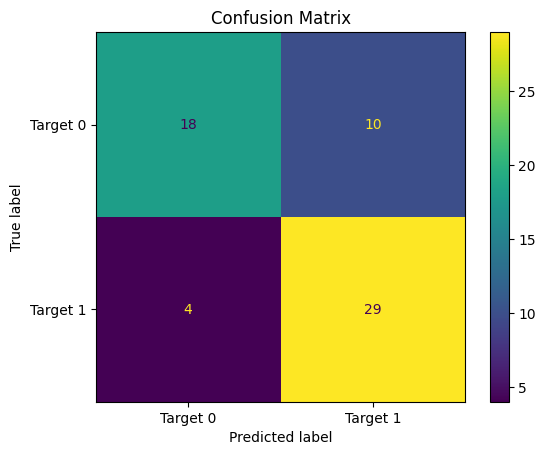

In [42]:
ConfusionMatrixDisplay.from_predictions(y_test , y_pred , display_labels= ['Target 0' , 'Target 1'])
plt.title('Confusion Matrix')
plt.show()

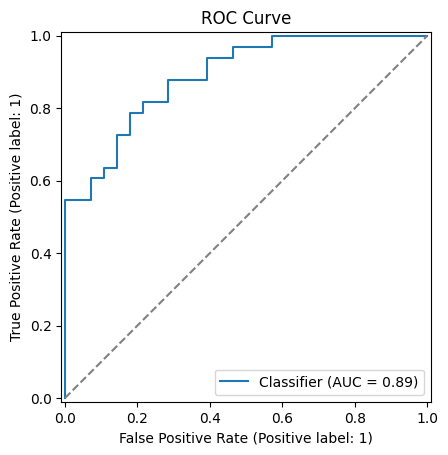

In [43]:
RocCurveDisplay.from_predictions(y_test , y_prob)
plt.plot([0 , 1] , [0 , 1] , ls= '--' , color= 'gray')
plt.title('ROC Curve')
plt.show()

In [44]:
roc_auc_score(y_test , y_prob)

0.8896103896103895

In [45]:
rng = np.random.RandomState(42)
aucs = []
for _ in range(1000):
    idx = rng.randint(0 , len(y_test) , len(y_test))
    if y_test.iloc[idx].nunique() < 2:
        continue
    aucs.append(roc_auc_score(y_test.iloc[idx] , y_prob[idx]))

np.percentile(aucs , [2.5 , 97.5])

array([0.80734123, 0.95804252])

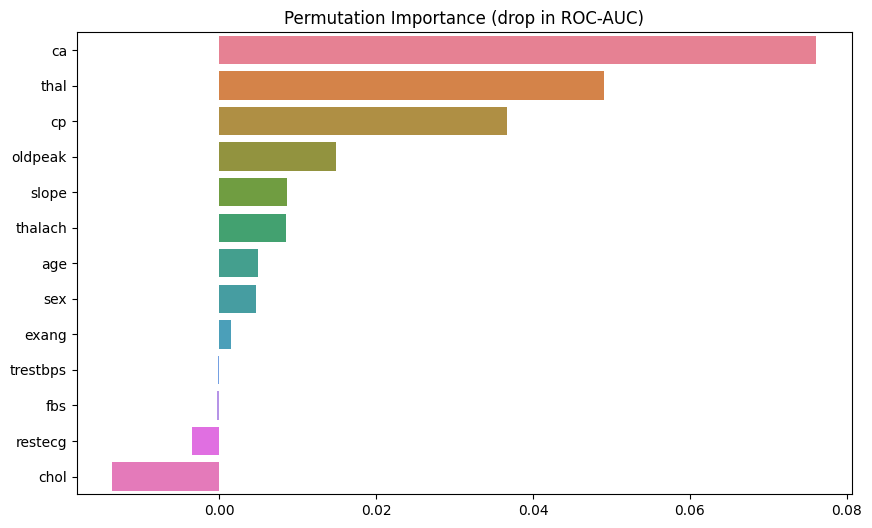

In [46]:
importance = permutation_importance(final_model , X_test , y_test , scoring= 'roc_auc' , n_repeats= 30 , random_state= 42)
importance_df = pd.Series(importance.importances_mean , index= X_test.columns).sort_values(ascending= False)

plt.figure(figsize= (10,6))
plt.title('Permutation Importance (drop in ROC-AUC)')
sns.barplot( x = importance_df.values , y= importance_df.index , hue= importance_df.index)
plt.ylabel('')
plt.show()